## 1. Load data

# Substitution network from user reviews

**Goal:** find which ingredients users actually swap, build a directed weighted substitution network, and derive the core ingredient list from it.

**Method**
1. **Phrase matching**: reviews are searched for replacement phrases. Teng et al. give "replace a with b", "substitute b for a" and "b instead of a" as examples; this notebook uses an extended pattern inventory (Section 3). The three published phrasings are flagged (`teng = True`) so that the gain of the extension can be measured.
2. **Ingredient identification**: the phrases *a* and *b* are mapped to the canonical ingredient list (`ingr_map.pkl`).
3. **Network construction**: directed network, edge *a → b* means "b was used instead of a".
4. **Thresholding**: edges supported by fewer than 5 reviews are removed.
5. **Edge weighting**: *w(a → b) = p(b | a)*, the share of all substitutions of *a* that suggest *b*.

**Own decisions:**
- an alias list for brand / colloquial names missing from `ingr_map` (e.g. *splenda*, *mayo*, *evoo*);
- words that are never an ingredient on their own (pronouns, *fresh*, *canned*, ...) are rejected;
- *light / low-fat / low-sodium* versions are kept as separate nodes, because `ingr_map` merges them into the base ingredient and would otherwise hide the most relevant health swaps;
- *water* is not treated as an ingredient: it has no nutritional value and its swaps concern flavour, not healthiness;
- a small merge list joins nodes that are the same food written differently (e.g. *white sugar → sugar*, *yoghurt → yogurt*), while nutritionally different variants (*greek yogurt*, *egg white*, *(light)* nodes) stay separate;
- the pattern *"changed a to b"* was tested and removed, because almost all of its matches were not substitutions (Section 3);
- each pair is counted once per review, and the mean star rating of the supporting reviews is stored on each edge.

**Section 9** applies community detection (Louvain) to derive ingredient categories from the network and builds the core ingredient list.

In [2]:
import re, sys, types
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

pd.set_option("display.max_colwidth", 120)

interactions = pd.read_csv("RAW_interactions.csv").dropna(subset=["review"])
interactions = interactions[interactions["review"].str.strip() != ""].reset_index(drop=True)

# ingr_map.pkl was written with an older pandas version; add a small compatibility shim if needed
try:
    ingr_map = pd.read_pickle("ingr_map.pkl")
except ModuleNotFoundError:
    shim = types.ModuleType("pandas.core.indexes.numeric")
    shim.Int64Index = shim.Float64Index = shim.UInt64Index = shim.NumericIndex = pd.Index
    sys.modules["pandas.core.indexes.numeric"] = shim
    ingr_map = pd.read_pickle("ingr_map.pkl")

pp_recipes = pd.read_csv("PP_recipes.csv", usecols=["id", "ingredient_ids"])
print("Reviews:", len(interactions), "| ingr_map rows:", len(ingr_map),
      "| canonical ingredients:", ingr_map["id"].nunique())

Reviews: 1132195 | ingr_map rows: 11659 | canonical ingredients: 8023


## 2. Ingredient lexicon (Teng step 2)

Every raw, processed and canonical string of `ingr_map` is normalised (lower case, crude singular) and mapped to its canonical id. A phrase from a review is mapped to the **longest** lexicon entry it contains.

Display names are the canonical names with the stemming artefacts of `ingr_map` repaired (e.g. *flmy → flour*).

In [3]:
def norm_token(t):
    # crude singularisation so that "eggs"/"egg" and "onions"/"onion" share one key
    if len(t) > 4 and t.endswith("ies"):
        return t[:-3] + "y"
    if len(t) > 4 and t.endswith("oes"):
        return t[:-2]
    if len(t) > 3 and t.endswith("s") and not t.endswith("ss"):
        return t[:-1]
    return t

def key(text):
    return " ".join(norm_token(t) for t in re.findall(r"[a-z]+(?:-[a-z]+)*", str(text).lower()))

lexicon = {}
for col in ["raw_ingr", "processed", "replaced"]:
    for name, ing_id in zip(ingr_map[col], ingr_map["id"]):
        k = key(name)
        if k:
            lexicon.setdefault(k, int(ing_id))

# Readable names: canonical name with the stemming artefacts of ingr_map repaired
STEM_FIX = {"flmy": "flour", "pastum": "pasta", "stevium": "stevia", "olife": "olive", "molass": "molasses",
            "asparagu": "asparagus", "spaghettus": "spaghetti", "chily": "chili", "hummu": "hummus",
            "couscou": "couscous", "truvium": "truvia"}
canonical = ingr_map.drop_duplicates("id").set_index("id")["replaced"]
display_name = canonical.apply(lambda s: " ".join(STEM_FIX.get(w, w) for w in s.split()))

# Own decision: brand / colloquial names missing from ingr_map -> an existing lexicon entry
ALIASES = {
    "splenda": "splenda granular", "half and half": "half-and-half", "panko": "panko breadcrumbs",
    "ricotta": "ricotta cheese", "mayo": "mayonnaise", "bbq sauce": "barbecue sauce", "sherry": "dry sherry",
    "provolone": "provolone cheese", "evoo": "olive oil", "egg beaters": "egg substitute",
    "eggbeaters": "egg substitute", "pam": "cooking spray", "canola": "canola oil", "dijon": "dijon mustard",
    "smart balance": "margarine", "oleo": "margarine", "crisco": "shortening", "stevia": "stevia powder",
    "truvia": "stevia powder", "agave": "agave nectar", "yoghurt": "yogurt", "greek yoghurt": "greek yogurt",
    "hamburger": "ground beef", "hamburger meat": "ground beef", "velveeta": "velveeta cheese",
}
added, missing = 0, []
for alias, target in ALIASES.items():
    if key(target) in lexicon:
        if key(alias) not in lexicon:
            lexicon[key(alias)] = lexicon[key(target)]
            added += 1
    else:
        missing.append(alias)
print("Lexicon entries:", len(lexicon), "| aliases added:", added, "| alias targets not found:", missing)

# Own decision: words that never denote an ingredient on their own.
# "water" is included on purpose: it has no nutritional value and its swaps (water -> broth/milk) concern flavour.
NON_INGREDIENT = {norm_token(w) for w in """it that this them those these one ones some any all my our your their
the a an of and or i we you he she they recipe fresh dried dry canned frozen regular plain white red yellow green
whole low fat light lite reduced free homemade store bought jar can cup cups tablespoon teaspoon tbsp tsp oz
ounce pound lb half bit little extra more less amount same other kind type brand version powder ground chopped
minced sliced water""".split()}

# Own decision: light / low-fat versions stay separate nodes (ingr_map merges them into the base ingredient)
LIGHT_RX = re.compile(r"\b(?:light|lite|low[- ]?fat|non[- ]?fat|fat[- ]?free|reduced[- ]?(?:fat|calorie|sodium|sugar)"
                      r"|low[- ]?sodium|no[- ]salt[- ]added|sugar[- ]?free|skim|diet|lean)\b")

print("Lexicon, aliases, non-ingredient words and the light rule are defined.")

Lexicon entries: 11438 | aliases added: 17 | alias targets not found: []
Lexicon, aliases, non-ingredient words and the light rule are defined.


### 2b. Merge decisions: which ingredient names mean the same food?

**Problem:** the same food often appears under several names ("butter", "unsalted butter", "real butter"). If these stay separate nodes, the evidence for one swap is split across several nodes and looks weaker than it is.

**Solution in three steps:**
1. **Automatic candidates.** Two names are candidates if they become identical after removing descriptive words. Only ingredients used in at least 50 recipes are checked.
2. **Suggested decision by a transparent rule:**
   - only *same-food words* differ (*fresh, real, unsalted, granulated, pure, plain, regular, all-purpose*, or only the spelling) → **merge**;
   - a *different-form word* is involved (*dried, dry, ground, whole, white, sweet, cooked*) → **keep separate**, because the food or its nutrition may differ (e.g. *sweet potato*, *dried cranberry*, *white chocolate*);
   - a short list of manually reviewed **exceptions** that contain a different-form word but are the same food in practice (*white sugar, white flour, white rice, white onion, whole milk*) → **merge**.
3. **Manual merges** that a name rule cannot find: synonyms and review language, e.g. reviewers write "oil" but mean vegetable oil, or "beef" but mean ground beef. Each has a written reason.

Nutritionally different variants with their own names (*greek yogurt, egg white, lean ground beef, unsweetened applesauce*) and all *(light)* nodes are never merged.

**Output:** everything is written to `merge_decisions.csv`, one row per ingredient, with the columns `decision` (*merge* / *keep* / *target*), `merge_into` and `reason`. The code then **reads the merges from this file**, so the table in the thesis appendix and the code can never differ.

**Editing:** the file is created only if it does not exist yet. To change a decision, edit the `decision` column in Excel and re-run the notebook; your edits are kept. To regenerate the suggestions, delete the file.

In [4]:
import os, collections

recipe_freq = pp_recipes["ingredient_ids"].str.findall(r"\d+").explode().astype(int).value_counts()
DECISIONS_FILE = "merge_decisions.csv"
MIN_RECIPES = 50

# --- Rule for the automatic candidates ---------------------------------------------------------
SAME_FOOD_WORDS = ["fresh", "real", "unsalted", "granulated", "pure", "plain", "regular", "all-purpose"]
DIFFERENT_FORM_WORDS = ["dried", "dry", "ground", "whole", "white", "sweet", "cooked"]
SAME_FOOD_EXCEPTIONS = {"white sugar", "white flour", "white rice", "white onion", "whole milk"}  # reviewed by hand

# --- Manual merges that a name rule cannot find (synonyms / review language) -------------------
MANUAL_MERGES = [  # (ingredient, merge_into, reason)
    ("cream", "heavy cream", "in reviews 'cream' means heavy / whipping cream"),
    ("whipping cream", "heavy cream", "same product, different name"),
    ("heavy whipping cream", "heavy cream", "same product, different name"),
    ("oil", "vegetable oil", "in reviews 'oil' means a neutral vegetable oil"),
    ("cooking oil", "vegetable oil", "same product, different name"),
    ("agave", "agave nectar", "same product, different name"),
    ("agave syrup", "agave nectar", "same product, different name"),
    ("truvia", "stevia", "brand name of a stevia sweetener"),
    ("beef", "ground beef", "in reviews 'beef' is used in ground-meat context (e.g. beef -> ground turkey)"),
    ("turkey", "ground turkey", "in reviews 'turkey' is used in ground-meat context"),
    ("garlic clove", "garlic", "same food, counted in cloves"),
    ("granulated garlic", "garlic powder", "granulated garlic is dried garlic, used like garlic powder (overrides the name rule)"),
]

word_rx = re.compile(r"\b(?:" + "|".join(SAME_FOOD_WORDS + DIFFERENT_FORM_WORDS) + r")\b")

def base_name(name):
    return " ".join(word_rx.sub("", name.replace("yoghurt", "yogurt")).split())

def suggest_decisions():
    groups = collections.defaultdict(list)
    for i, n in display_name.items():
        if recipe_freq.get(int(i), 0) >= MIN_RECIPES:
            groups[base_name(n)].append((n, int(recipe_freq[int(i)])))
    rows = []
    for base, members in sorted(groups.items()):
        if len(members) < 2:
            continue
        names = [m[0] for m in members]
        target = base if base in names else max(members, key=lambda m: m[1])[0]
        for name, n_rec in members:
            removed = word_rx.findall(name)
            if name == target:
                decision, into, reason = "target", "", "the name the others are merged into"
            elif name in SAME_FOOD_EXCEPTIONS:
                decision, into, reason = "merge", target, "reviewed exception: same food in practice"
            elif all(w in SAME_FOOD_WORDS for w in removed):
                decision, into = "merge", target
                reason = f"only descriptive word(s) differ: {', '.join(removed)}" if removed else "spelling variant"
            else:
                decision, into = "keep", ""
                reason = f"'{[w for w in removed if w in DIFFERENT_FORM_WORDS][0]}' may change the food or its nutrition"
            rows.append({"group": base, "ingredient": name, "recipes": n_rec, "decision": decision,
                         "merge_into": into, "reason": reason, "source": "automatic name rule"})
    auto = pd.DataFrame(rows)
    manual = pd.DataFrame([{"group": into, "ingredient": n, "recipes": int(recipe_freq.get(name_to_id.get(n, -1), 0)),
                            "decision": "merge", "merge_into": into, "reason": r, "source": "manual (synonym / review language)"}
                           for n, into, r in MANUAL_MERGES])
    auto = auto[~auto["ingredient"].isin(manual["ingredient"])]      # a manual decision overrides the rule
    return pd.concat([auto, manual], ignore_index=True)

name_to_id = {}
for i, n in display_name.items():
    name_to_id.setdefault(n, int(i))

if not os.path.exists(DECISIONS_FILE):
    suggest_decisions().to_csv(DECISIONS_FILE, index=False, sep=";", encoding="utf-8-sig")  # ";" opens correctly in Excel
    print(f"Created {DECISIONS_FILE} with the suggested decisions.")
else:
    print(f"Using the existing {DECISIONS_FILE} (your edits are kept; delete the file to regenerate it).")

decisions = pd.read_csv(DECISIONS_FILE, sep=";", encoding="utf-8-sig").fillna("")
display(pd.crosstab(decisions["source"], decisions["decision"], margins=True))

# Build the merge rules from the table (and resolve chains such as a -> b -> c)
merges = decisions[decisions["decision"].str.strip().str.lower() == "merge"]
MERGE_ID = {}
for src, dst in zip(merges["ingredient"], merges["merge_into"]):
    if src in name_to_id and dst in name_to_id and src != dst:
        MERGE_ID[name_to_id[src]] = name_to_id[dst]
    else:
        print("merge row skipped (name not found):", src, "->", dst)
for k in list(MERGE_ID):
    while MERGE_ID[k] in MERGE_ID:
        MERGE_ID[k] = MERGE_ID[MERGE_ID[k]]
print("Merge rules applied:", len(MERGE_ID))

print("\nExamples:")
display(decisions[decisions["group"].isin(["butter", "sugar", "yogurt", "cranberry", "potato"])]
        [["group", "ingredient", "recipes", "decision", "merge_into", "reason"]])

Using the existing merge_decisions.csv (your edits are kept; delete the file to regenerate it).


decision,keep,merge,target,All
source,,,,
automatic name rule,170,91,184,445
manual (synonym / review language),0,12,0,12
All,170,103,184,457


Merge rules applied: 103

Examples:


,group,ingredient,recipes,decision,merge_into,reason
64,butter,sweet unsalted butter,57,keep,,'sweet' may change the food or its nutrition
65,butter,butter,43970,target,,the name the others are merged into
66,butter,real butter,93,merge,butter,only descriptive word(s) differ: real
67,butter,unsalted butter,5414,merge,butter,only descriptive word(s) differ: unsalted
68,butter,sweet butter,109,keep,,'sweet' may change the food or its nutrition
138,cranberry,cranberry,478,target,,the name the others are merged into
139,cranberry,fresh cranberry,432,merge,cranberry,only descriptive word(s) differ: fresh
140,cranberry,dried cranberry,1050,keep,,'dried' may change the food or its nutrition
336,potato,white potato,180,keep,,'white' may change the food or its nutrition
337,potato,sweet potato,1615,keep,,'sweet' may change the food or its nutrition


### 2c. The mapping function

`map_phrase()` translates a phrase from a review into an ingredient node: it looks for the **longest** dictionary entry inside the phrase, skips non-ingredient words, applies the merge decisions of 2b, and creates a separate *(light)* node when the phrase names a light / low-fat version. The test lines below check the behaviour on typical phrases.

In [5]:
def map_phrase(phrase, prefer="first"):
    """Return (node, name) for the longest ingredient inside the phrase, or None."""
    toks = key(phrase).split()
    for n in range(min(5, len(toks)), 0, -1):
        grams = [(s, " ".join(toks[s:s + n])) for s in range(len(toks) - n + 1)]
        if prefer == "last":            # for "b instead of a": take the ingredient closest to the cue
            grams = grams[::-1]
        for s, g in grams:
            if all(t in NON_INGREDIENT for t in toks[s:s + n]) or g not in lexicon:
                continue
            ing_id = MERGE_ID.get(lexicon[g], lexicon[g])
            name = display_name.get(ing_id, str(ing_id))
            if LIGHT_RX.search(phrase) and not LIGHT_RX.search(name):
                return f"{ing_id}_light", f"{name} (light)"
            return str(ing_id), name
    return None

for test in ["fresh basil", "unsweetened applesauce", "eggs", "splenda", "it", "dried", "low-fat sour cream",
             "white sugar", "the light mayo", "lean ground beef", "yoghurt", "water"]:
    print(f"{test!r:24} -> {map_phrase(test)}")

'fresh basil'            -> ('382', 'basil')
'unsweetened applesauce' -> ('7396', 'unsweetened applesauce')
'eggs'                   -> ('2499', 'egg')
'splenda'                -> ('208', 'artificial sweetener')
'it'                     -> None
'dried'                  -> None
'low-fat sour cream'     -> ('6654_light', 'sour cream (light)')
'white sugar'            -> ('6906', 'sugar')
'the light mayo'         -> ('4623_light', 'mayonnaise (light)')
'lean ground beef'       -> ('4189', 'lean ground beef')
'yoghurt'                -> ('7998', 'yogurt')
'water'                  -> None


## 3. Phrase matching (Teng step 1, extended pattern inventory)

*a* = replaced ingredient, *b* = replacement. Every pattern fixes the direction explicitly. A phrase ends at punctuation or at a function word. For patterns where *b* stands **before** the cue (e.g. "used honey instead of sugar"), the text window before the cue is read from the right, so the ingredient nearest to the cue is taken.

`teng = True` marks the three phrasings published by Teng et al.; the others are the extension.

In [6]:
NP = r"([a-z][a-z\-' ]{0,40}?)"                       # short phrase, lazy
WIN = r"([a-z\-' ]{1,40})"                             # window before a cue (no punctuation)
STOP = (r"(?=\s*(?:[.,;:!?()\n]|\band\b|\bbut\b|\bbecause\b|\bsince\b|\bso\b|\bwhich\b|\bwhen\b|\bas\b"
        r"|\bin\b|\bfor\b|\bwith\b|\bto\b|\bit\b|\bthey\b|\bthen\b|\bon\b|\bi\b|\bwe\b|$))")
DET = r"(?:the\s+|a\s+|an\s+|some\s+|my\s+)?"
SUB = r"(?:substitut(?:e|ed|ing)|sub(?:bed|bing)?)"

# name: (regex, group of a, group of b, phrase-reading direction for b, Teng phrasing?)
PATTERNS = {
    "replace a with b":         (rf"\breplac(?:e|ed|ing)\s+{DET}{NP}\s+(?:with|by)\s+{DET}{NP}{STOP}", 1, 2, "first", True),
    "substitute b for a":       (rf"\b{SUB}\s+{DET}{NP}\s+for\s+{DET}{NP}{STOP}", 2, 1, "first", True),
    "b instead of a":           (rf"{WIN}\s+instead\s+of\s+{DET}{NP}{STOP}", 2, 1, "last", True),
    "a was replaced with b":    (rf"{WIN}\s+(?:was|were)\s+replaced\s+(?:with|by)\s+{DET}{NP}{STOP}", 1, 2, "first", False),
    "substitute a with b":      (rf"\b{SUB}\s+{DET}{NP}\s+with\s+{DET}{NP}{STOP}", 1, 2, "first", False),
    "swap/switch a for b":      (rf"\b(?:swap(?:ped|ping)?|switch(?:ed|ing)?|trad(?:e|ed)|exchang(?:e|ed))\s+(?:out\s+)?{DET}{NP}\s+(?:for|with|to)\s+{DET}{NP}{STOP}", 1, 2, "first", False),
    "switched from a to b":     (rf"\bswitch(?:ed|ing)?\s+from\s+{DET}{NP}\s+to\s+{DET}{NP}{STOP}", 1, 2, "first", False),
    # "changed a to b" was tested and removed: 94% of its 8,784 matches were not substitutions
    # ("the only change I made was to add ..."), and it contributed only 0.7% of the mapped pairs.
    "used b as substitute for a": (rf"\b(?:used?|using)\s+{DET}{NP}\s+as\s+(?:a\s+)?(?:substitute|replacement|sub)\s+for\s+{DET}{NP}{STOP}", 2, 1, "first", False),
    "b is a good substitute for a": (rf"{WIN}\s+(?:is|was|makes)\s+(?:a\s+)?(?:good\s+|great\s+|nice\s+|fine\s+)?(?:substitute|replacement|sub)\s+for\s+{DET}{NP}{STOP}", 2, 1, "last", False),
    "b in place of / rather than a": (rf"{WIN}\s+(?:in\s+place\s+of|rather\s+than)\s+{DET}{NP}{STOP}", 2, 1, "last", False),
    "instead of a, I used b":   (rf"\b(?:instead\s+of|in\s+place\s+of)\s+{DET}{NP}\s*,?\s*(?:i|we)\s+(?:used|use|added|put\s+in|substituted|went\s+with)\s+{DET}{NP}{STOP}", 1, 2, "first", False),
}
PATTERNS = {k: (re.compile(rx), ga, gb, rd, teng) for k, (rx, ga, gb, rd, teng) in PATTERNS.items()}

CUE_RX = r"replac|substitut|\bsub(?:bed|bing)?\b|swap|switch|trade|exchang|instead of|in place of|rather than"
cue = interactions["review"].str.contains(CUE_RX, case=False, regex=True)
candidates = interactions[cue]
print(f"Reviews containing a cue word: {len(candidates):,} ({cue.mean() * 100:.1f}% of all reviews)")

Reviews containing a cue word: 161,619 (14.3% of all reviews)


In [7]:
rows = []
for rev_idx, text, rating in zip(candidates.index, candidates["review"].str.lower(), candidates["rating"]):
    for pname, (rx, ga, gb, read_b, teng) in PATTERNS.items():
        for m in rx.finditer(text):
            a_phrase, b_phrase = m.group(ga).strip(), m.group(gb).strip()
            read_a = "last" if ga == 1 and pname.startswith("a was") else "first"
            a = map_phrase(a_phrase, prefer=read_a)
            b = map_phrase(b_phrase, prefer=read_b)
            if a is None or b is None:
                status = "unmapped"
            elif a[0] == b[0]:
                status = "same ingredient"       # e.g. "2 eggs instead of 3 eggs"
            else:
                status = "mapped"
            rows.append((rev_idx, rating, pname, teng, a_phrase, b_phrase,
                         a[0] if a else None, a[1] if a else None, b[0] if b else None, b[1] if b else None,
                         status, text[max(0, m.start() - 60): m.end() + 40]))

ext = pd.DataFrame(rows, columns=["review_idx", "rating", "pattern", "teng", "a_phrase", "b_phrase",
                                  "a_node", "a_name", "b_node", "b_name", "status", "context"])
print(f"Extracted candidate phrases: {len(ext):,}")
summary = pd.crosstab(ext["pattern"], ext["status"], margins=True)
display(summary.sort_values("All", ascending=False))

Extracted candidate phrases: 129,368


status,mapped,same ingredient,unmapped,All
pattern,,,,
All,76677,1896,50795,129368
b instead of a,44771,1034,34339,80144
b in place of / rather than a,11689,320,8375,20384
substitute b for a,11582,221,3749,15552
"instead of a, I used b",3702,183,1426,5311
replace a with b,2385,61,1147,3593
substitute a with b,1536,58,850,2444
swap/switch a for b,838,16,714,1568
used b as substitute for a,100,1,50,151


In [8]:
# Input for improving the alias list: what is still not mapped?
unm = ext[ext["status"] == "unmapped"]
print("Most frequent unmapped replacement phrases (b):")
print(unm.loc[unm["b_node"].isna(), "b_phrase"].value_counts().head(20).to_dict())
print("\nMost frequent unmapped replaced phrases (a):")
print(unm.loc[unm["a_node"].isna(), "a_phrase"].value_counts().head(20).to_dict())

Most frequent unmapped replacement phrases (b):
{'': 3153, 'and': 910, 'but': 293, 'so': 257, 'half': 190, 'water': 184, 'it': 164, 'minutes': 124, 'i used half and half': 113, 'also': 96, 'this': 94, 'so i used that': 76, 'that': 70, 'half and half': 67, 'i used water': 63, 'this one': 60, 'then': 49, 'hours': 44, 'them': 43, 'fresh': 36}

Most frequent unmapped replaced phrases (a):
{'water': 3007, 'fresh': 1131, 'white': 811, 'canned': 755, 'it': 641, 'green': 559, 'regular': 467, 'red': 438, 'dried': 411, 'half': 406, 'powder': 375, 'frozen': 355, 'one': 286, 'breasts': 254, 'frying': 189, 'thighs': 187, 'plain': 176, 'two': 174, 'swiss': 170, 'baking': 163}


## 4. Edges: thresholding and weighting (Teng steps 3–5)

$$w(a \rightarrow b) = p(b \mid a) = \frac{n(a \rightarrow b)}{\sum_{b'} n(a \rightarrow b')}$$

*n* counts reviews (a pair is counted once per review). Edges with *n < 5* are removed, as in Teng et al. *p(b|a)* is computed over all mapped substitutions of *a*.

In [9]:
MIN_SUPPORT = 5

def build_edges(extractions):
    pairs = extractions[extractions["status"] == "mapped"].drop_duplicates(["review_idx", "a_node", "b_node"])
    e = (pairs.groupby(["a_node", "b_node"])
         .agg(a=("a_name", "first"), b=("b_name", "first"), support=("review_idx", "count"),
              mean_rating=("rating", lambda r: r[r > 0].mean()))
         .reset_index())
    e["weight"] = e["support"] / e.groupby("a_node")["support"].transform("sum")   # p(b|a)
    return e[e["support"] >= MIN_SUPPORT].sort_values("support", ascending=False).reset_index(drop=True)

edges = build_edges(ext)
edges_teng = build_edges(ext[ext["teng"]])

comparison = pd.DataFrame({
    "Teng phrasings only": [int((ext["teng"] & (ext["status"] == "mapped")).sum()), len(edges_teng),
                            pd.concat([edges_teng["a_node"], edges_teng["b_node"]]).nunique()],
    "Extended inventory": [int((ext["status"] == "mapped").sum()), len(edges),
                           pd.concat([edges["a_node"], edges["b_node"]]).nunique()],
}, index=["mapped extractions", f"edges (support >= {MIN_SUPPORT})", "ingredients (nodes)"])
display(comparison)

print("Top 25 substitutions:")
display(edges[["a", "b", "support", "weight", "mean_rating"]].head(25).round(3))

,Teng phrasings only,Extended inventory
mapped extractions,58738,76677
edges (support >= 5),1808,2340
ingredients (nodes),745,867


Top 25 substitutions:


,a,b,support,weight,mean_rating
0,sugar,artificial sweetener,1886,0.537,4.792
1,butter,olive oil,847,0.261,4.748
2,margarine,butter,658,0.698,4.768
3,vegetable oil,applesauce,549,0.253,4.702
4,heavy cream,milk,469,0.287,4.709
5,ground beef,ground turkey,461,0.324,4.704
6,walnut,pecan,459,0.576,4.812
7,sugar,honey,455,0.130,4.758
8,shortening,butter,437,0.583,4.644
9,vegetable oil,butter,414,0.191,4.721


## 5. The substitution network

In [10]:
G = nx.DiGraph()
for r in edges.itertuples():
    G.add_edge(r.a_node, r.b_node, weight=r.weight, support=int(r.support), mean_rating=float(r.mean_rating))
names = dict(zip(edges["a_node"], edges["a"])) | dict(zip(edges["b_node"], edges["b"]))
nx.set_node_attributes(G, names, "name")

largest = max(nx.weakly_connected_components(G), key=len)
print(f"Nodes: {G.number_of_nodes():,} | Edges: {G.number_of_edges():,} | Density: {nx.density(G):.4f}")
print(f"Weakly connected components: {nx.number_weakly_connected_components(G)} | "
      f"largest: {len(largest)} nodes ({len(largest) / G.number_of_nodes() * 100:.1f}%)")

edges.to_csv("substitution_edges.csv", index=False)
nx.write_graphml(G, "substitution_graph.graphml")
print("Saved substitution_edges.csv and substitution_graph.graphml")

Nodes: 867 | Edges: 2,340 | Density: 0.0031
Weakly connected components: 20 | largest: 823 nodes (94.9%)
Saved substitution_edges.csv and substitution_graph.graphml


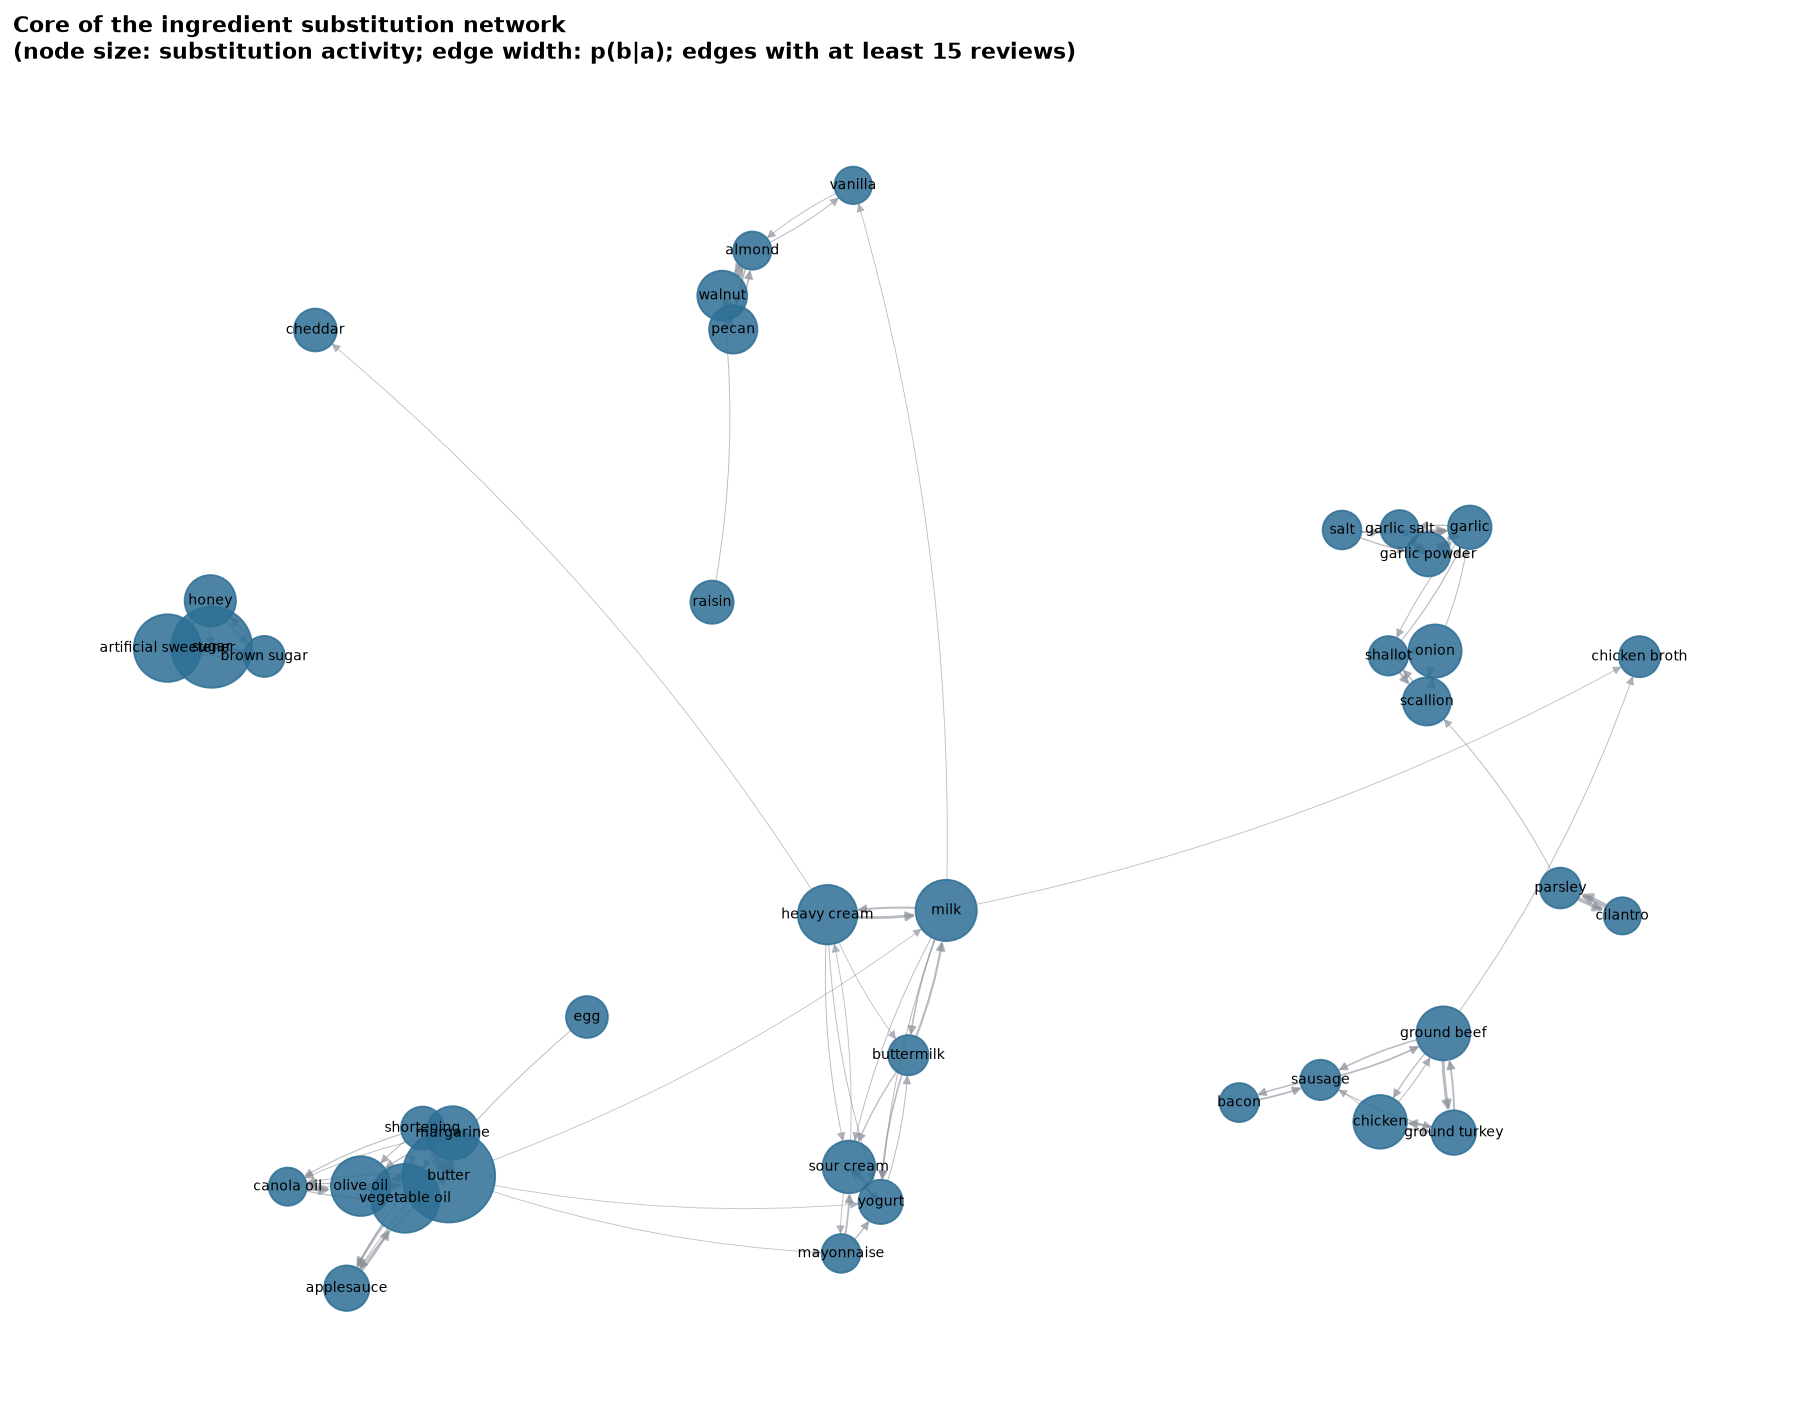

In [11]:
# Figure: the core of the network (40 ingredients with the most substitution activity)
activity = pd.Series({n: G.in_degree(n, weight="support") + G.out_degree(n, weight="support") for n in G.nodes})
core = activity.sort_values(ascending=False).head(40).index
H = G.subgraph(core).copy()
H.remove_edges_from([(u, v) for u, v, d in H.edges(data=True) if d["support"] < 15])
H.remove_nodes_from(list(nx.isolates(H)))

plt.figure(figsize=(14, 11), dpi=130)
pos = nx.spring_layout(H, k=0.9, weight="support", seed=7)
size = [activity[n] / activity.max() * 2500 + 150 for n in H.nodes]
width = [0.4 + 4 * d["weight"] for _, _, d in H.edges(data=True)]
nx.draw_networkx_nodes(H, pos, node_size=size, node_color="#2E6F95", alpha=0.85)
nx.draw_networkx_edges(H, pos, width=width, edge_color="#8A8F98", alpha=0.6, arrowsize=10,
                       connectionstyle="arc3,rad=0.08", node_size=size)
nx.draw_networkx_labels(H, pos, labels={n: H.nodes[n]["name"] for n in H.nodes}, font_size=8)
plt.title("Core of the ingredient substitution network\n(node size: substitution activity; "
          "edge width: p(b|a); edges with at least 15 reviews)", loc="left", fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.savefig("fig_substitution_network.png", bbox_inches="tight")
plt.show()

## 6. Swappable ingredients

`suggest_swaps(ingredient)` lists the substitutes users reported for an ingredient, ranked by *p(b | a)*, with the number of supporting reviews and their mean rating. This is the review-based swap feature; whether a swap is *healthier* is decided later with the FoodData Central macro dictionary.

In [12]:
def suggest_swaps(ingredient, top=10):
    hit = map_phrase(ingredient)
    if hit is None or hit[0] not in G:
        return f"No substitutes with at least {MIN_SUPPORT} reviews for '{ingredient}'."
    out = [(G.nodes[b]["name"], d["weight"], d["support"], d["mean_rating"]) for _, b, d in G.out_edges(hit[0], data=True)]
    return (pd.DataFrame(out, columns=["substitute", "p(b|a)", "reviews", "mean_rating"])
            .sort_values("p(b|a)", ascending=False).head(top).reset_index(drop=True).round(3))

for ing in ["butter", "sugar", "sour cream", "ground beef", "heavy cream", "oil"]:
    print(f"\n=== Substitutes for '{ing}' ===")
    display(suggest_swaps(ing))


=== Substitutes for 'butter' ===


,substitute,p(b|a),reviews,mean_rating
0,olive oil,0.261,847,4.748
1,margarine,0.128,414,4.758
2,vegetable oil,0.102,330,4.737
3,applesauce,0.059,190,4.777
4,coconut oil,0.057,186,4.744
5,canola oil,0.045,145,4.738
6,cooking spray,0.036,116,4.667
7,shortening,0.021,69,4.556
8,apple,0.013,42,4.738
9,margarine (light),0.012,39,4.821



=== Substitutes for 'sugar' ===


,substitute,p(b|a),reviews,mean_rating
0,artificial sweetener,0.537,1886,4.792
1,honey,0.130,455,4.758
2,brown sugar,0.062,216,4.707
3,stevia,0.039,136,4.720
4,agave nectar,0.028,98,4.722
5,maple syrup,0.019,68,4.677
6,sucanat,0.012,42,4.829
7,coconut sugar,0.006,22,4.941
8,dark brown sugar,0.005,18,4.647
9,powdered sugar,0.005,16,4.714



=== Substitutes for 'sour cream' ===


,substitute,p(b|a),reviews,mean_rating
0,yogurt,0.286,287,4.716
1,greek yogurt,0.163,164,4.730
2,yogurt (light),0.132,133,4.795
3,cream cheese,0.035,35,4.667
4,cottage cheese,0.035,35,4.909
5,greek yogurt (light),0.034,34,4.935
6,vanilla yogurt,0.026,26,4.640
7,mayonnaise,0.023,23,4.682
8,creme fraiche,0.020,20,4.895
9,heavy cream,0.015,15,4.750


... (2 outputs left out)


=== Substitutes for 'heavy cream' ===


,substitute,p(b|a),reviews,mean_rating
0,milk,0.287,469,4.709
1,evaporated milk,0.061,99,4.750
2,skim milk,0.045,73,4.817
3,cream of mushroom soup,0.034,55,4.630
4,sour cream,0.032,52,4.708
5,milk (light),0.032,52,4.776
6,half-and-half,0.029,48,4.875
7,yogurt,0.029,47,4.795
8,cream of chicken soup,0.021,35,4.667
9,evaporated milk (light),0.018,30,4.900



=== Substitutes for 'oil' ===


,substitute,p(b|a),reviews,mean_rating
0,applesauce,0.253,549,4.702
1,butter,0.191,414,4.721
2,olive oil,0.108,235,4.805
3,apple,0.055,119,4.741
4,cooking spray,0.039,85,4.690
5,unsweetened applesauce,0.037,81,4.636
6,coconut oil,0.037,80,4.838
7,sesame oil,0.022,47,4.841
8,canola oil,0.015,33,4.667
9,bacon grease,0.013,29,4.885


## 7. Ingredient ranking derived from the network

This table is the data-driven basis for the core ingredient list. For every node:
- **times_replaced**: reviews in which users replaced this ingredient (weighted out-degree);
- **times_used_as_substitute**: reviews in which it was the replacement (weighted in-degree);
- **n_substitutes / n_replaces**: number of distinct partners (out- / in-degree);
- **recipes**: number of recipes in `PP_recipes.csv` that contain it.

Ingredients that are often *replaced* are candidates for the "common" role; ingredients often *used as substitutes* are candidates for the "alternative" role.

In [13]:
ranking = pd.DataFrame({
    "node": list(G.nodes),
    "ingredient": [G.nodes[n]["name"] for n in G.nodes],
    "times_replaced": [G.out_degree(n, weight="support") for n in G.nodes],
    "times_used_as_substitute": [G.in_degree(n, weight="support") for n in G.nodes],
    "n_substitutes": [G.out_degree(n) for n in G.nodes],
    "n_replaces": [G.in_degree(n) for n in G.nodes],
    "recipes": [int(recipe_freq.get(int(n.split("_")[0]), 0)) for n in G.nodes],
})
ranking["activity"] = ranking["times_replaced"] + ranking["times_used_as_substitute"]
ranking = ranking.sort_values("activity", ascending=False).reset_index(drop=True)
ranking.to_csv("substitution_ingredient_ranking.csv", index=False, encoding="utf-8-sig")

print("Ingredients in the network:", len(ranking))
print("Top 30 by substitution activity:")
display(ranking.head(30))

Ingredients in the network: 867
Top 30 by substitution activity:


,node,ingredient,times_replaced,times_used_as_substitute,n_substitutes,n_replaces,recipes,activity
0,840,butter,2882,1865,55,20,43970,4747
1,6906,sugar,3169,373,36,11,33884,3542
2,7557,vegetable oil,1899,582,37,13,10593,2481
3,208,artificial sweetener,316,2061,5,4,2003,2377
4,4717,milk,1127,776,42,24,22063,1903
5,5006,olive oil,321,1473,13,18,31834,1794
6,3668,heavy cream,1374,403,46,16,3437,1777
7,3484,ground beef,1184,232,33,9,4732,1416
8,1240,chicken,910,480,41,24,1851,1390
9,4574,margarine,853,530,8,5,4416,1383


## 8. Validation sample

100 randomly drawn mapped extractions are exported to `validation_sample.csv`. Mark each row in `correct` with **y** (real substitution, right ingredients, right direction) or **n**, and add a short note for errors. Precision = share of *y*. The same `random_state` always reproduces the same sample. The file uses `;` as separator and the line breaks inside reviews are removed, so it opens correctly in (Hungarian) Excel.

In [14]:
sample = (ext[ext["status"] == "mapped"].sample(100, random_state=42)
          [["pattern", "context", "a_phrase", "a_name", "b_phrase", "b_name"]]
          .assign(correct="", note=""))
sample["context"] = sample["context"].str.replace(r"\s+", " ", regex=True)          # no line breaks inside a cell
sample.to_csv("validation_sample.csv", index=False, sep=";", encoding="utf-8-sig")      # ";" opens correctly in Excel   # utf-8-sig opens cleanly in Excel
print("Saved validation_sample.csv;", sample["pattern"].value_counts().to_dict())
display(sample.head(5))

Saved validation_sample.csv; {'b instead of a': 55, 'b in place of / rather than a': 21, 'substitute b for a': 14, 'instead of a, I used b': 4, 'replace a with b': 3, 'swap/switch a for b': 2, 'substitute a with b': 1}


,pattern,context,a_phrase,a_name,b_phrase,b_name,correct,note
125491,substitute b for a,"ade tartar sauce that went into the one-cup of mayo, too. subbed dijon for the brown spicy mustard. and used mostly ...",brown spicy mustard,spicy mustard,dijon,dijon mustard,,
34555,b instead of a,"icer and make the slice very thin, followed recipe but added some lemon juice and used curly parsley instead of the ...",cilantro,cilantro,some lemon juice and used curly parsley,lemon juice,,
5012,b instead of a,"hen. saut&eacute;ed spinach instead of onions, onion powder, garlic olive oil instead of chopped garlic; no worceste...",chopped garlic,garlic,garlic olive oil,olive oil,,
47852,b instead of a,yummo! i now realize the key to a fabulous smoothie is using frozen fruit instead of ice cubes. that way you get the...,ice cubes,ice cube,fabulous smoothie is using frozen fruit,frozen fruit,,
9246,b instead of a,"i halved the recipe, used veggie bacon bits and dried cranberries instead of cherries. just delicious! thanks for po...",cherries,cherry,veggie bacon bits and dried cranberries,dried cranberry,,


## 9. Ingredient categories and the core ingredient list

Part 9 answers two questions: **which ingredient categories exist** (9a) and **which ingredients the app should focus on** (9b). Both are derived from the network with documented rules instead of being chosen by hand.

### 9a. Categories by community detection

**Idea:** in the figure of Section 5 the network forms clusters by itself (fats, sweeteners, dairy, ...). Teng et al. observed the same and identified such clusters with a community detection algorithm. Here the **Louvain method** (Blondel et al., 2008; built into NetworkX) is used. It groups the ingredients so that there are many swaps *inside* a group and few *between* groups, measured by **modularity** (values above about 0.3 indicate a clear community structure).

**Settings:** edge direction is ignored (a swap in either direction means the two ingredients are interchangeable), the edge weight is the number of supporting reviews, and the random seed is fixed so that the result is reproducible.

**Why these settings?**
- *Undirected:* for a category the question is "are these two ingredients interchangeable?", not "which way do users swap them?".
- *Weight = number of reviews:* a swap mentioned in 800 reviews should bind two ingredients more strongly than one mentioned in 5.
- *Resolution = 1.0:* the standard value of the algorithm. Higher values give more, smaller communities; lower values give fewer, larger ones. The default was kept so that the categories are not tuned by hand.
- *Seed = 42:* Louvain contains a random element; a fixed seed makes every run give the same communities.

In [15]:
U = nx.Graph()
for u, v, d in G.edges(data=True):
    w = d["support"] + (U[u][v]["weight"] if U.has_edge(u, v) else 0)
    U.add_edge(u, v, weight=w)

communities = nx.community.louvain_communities(U, weight="weight", resolution=1.0, seed=42)
communities = sorted(communities, key=lambda c: -sum(activity[n] for n in c))
modularity = nx.community.modularity(U, communities, weight="weight")
node_comm = {n: i for i, c in enumerate(communities) for n in c}
ranking["community"] = ranking["node"].map(node_comm)

print(f"Communities: {len(communities)} | modularity: {modularity:.3f}")
total_activity = activity.sum()
summary = pd.DataFrame([{
    "community": i,
    "size": len(c),
    "activity_share_%": round(sum(activity[n] for n in c) / total_activity * 100, 1),
    "top members": ", ".join(G.nodes[n]["name"] for n in sorted(c, key=lambda n: -activity[n])[:8]),
} for i, c in enumerate(communities)])
pd.set_option("display.max_colwidth", 150)
display(summary.head(15))

Communities: 39 | modularity: 0.847


,community,size,activity_share_%,top members
0,0,50,16.1,"butter, vegetable oil, olive oil, margarine, applesauce, shortening, canola oil, coconut oil"
1,1,122,12.7,"ground beef, chicken, ground turkey, chicken broth, sausage, bacon, ham, wine"
2,2,82,12.0,"milk, heavy cream, sour cream, yogurt, buttermilk, mayonnaise, cottage cheese, ricotta cheese"
3,3,34,10.3,"sugar, artificial sweetener, honey, brown sugar, maple syrup, agave nectar, molasses, stevia"
4,4,46,8.6,"onion, scallion, garlic powder, garlic, shallot, salt, garlic salt, onion powder"
5,5,105,6.8,"mushroom, celery, jalapeno, spinach, carrot, broccoli, pea, potato"
6,6,91,5.5,"flour, bread crumb, cornstarch, breadcrumb, bread, corn, tortilla, panko breadcrumb"
7,7,43,5.2,"walnut, pecan, almond, vanilla, almond extract, pine nut, cashew, peanut"
8,8,53,4.1,"raisin, chocolate chip, dried cranberry, nut, blueberry, strawberry, peanut butter, craisin"
9,9,20,3.5,"parsley, cilantro, basil, oregano, thyme, italian seasoning, rosemary, dill"


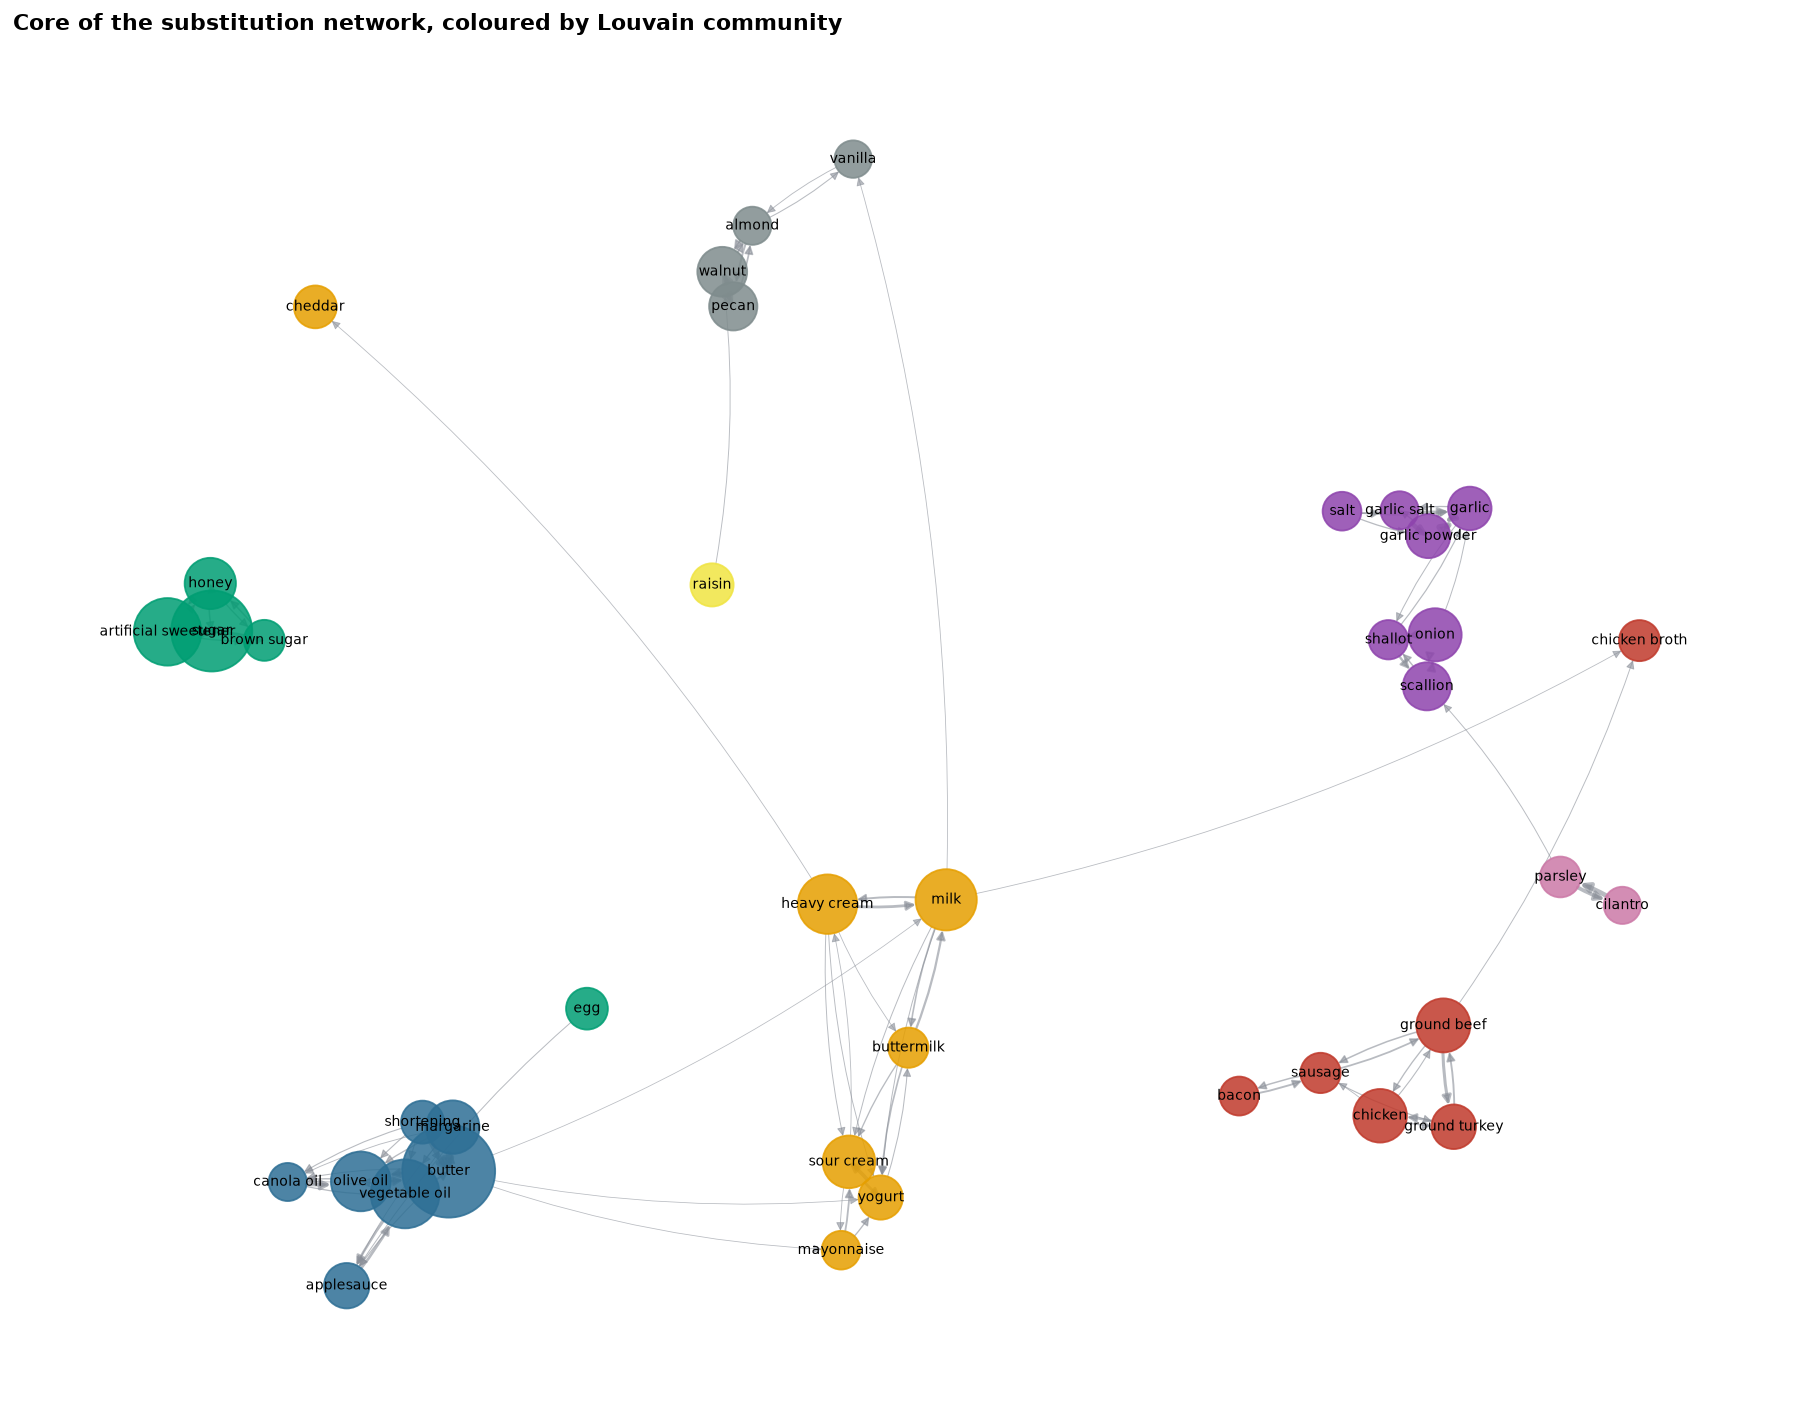

In [16]:
# Figure: the core network coloured by community
palette = ["#2E6F95", "#C0392B", "#E69F00", "#009E73", "#8E44AD", "#D55E00", "#56B4E9", "#7F8C8D", "#F0E442", "#CC79A7"]
plt.figure(figsize=(14, 11), dpi=130)
colors = [palette[node_comm[n] % len(palette)] for n in H.nodes]
nx.draw_networkx_nodes(H, pos, node_size=size, node_color=colors, alpha=0.85)
nx.draw_networkx_edges(H, pos, width=width, edge_color="#8A8F98", alpha=0.6, arrowsize=10,
                       connectionstyle="arc3,rad=0.08", node_size=size)
nx.draw_networkx_labels(H, pos, labels={n: H.nodes[n]["name"] for n in H.nodes}, font_size=8)
plt.title("Core of the substitution network, coloured by Louvain community", loc="left", fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.savefig("fig_substitution_communities.png", bbox_inches="tight")
plt.show()

**How to read the output of 9a**

- **Communities / modularity:** the number of groups found and the quality of the grouping. Modularity runs from 0 to 1; above about 0.3 counts as a clear structure. In the current run it is about **0.85**, which means ingredients form very distinct "swap families": users replace butter with other fats and sugar with other sweeteners, and almost never across families.
- **Table columns:**
  - `size`: the number of ingredients in the community;
  - `activity_share_%`: the share of all swap activity that happens inside it, which shows how important the community is;
  - `top members`: its 8 most active ingredients, which make the community easy to recognise and name (e.g. butter, oil, margarine → *fats & oils*).
- **The figure** shows the same core network as in Part 5, with each community in its own colour.
- **For the thesis:** the categories were *found by the algorithm from user behaviour*, not defined by the author. They match common-sense food groups, which supports both the method and the idea that the network captures real culinary knowledge (as also reported by Teng et al., 2012).
- **Limitation:** a few members are artefacts of how reviews are written. For example, "wine" lands in the meat community and "mushroom" in the dairy community (from swaps like *cream → cream of mushroom soup*). These are handled in 9b.

### 9b. Core ingredient list

**Selection rule (documented, reproducible):**
1. Only communities holding at least 3% of the total substitution activity are used; smaller ones are niche groups.
2. From each of these communities, the 10 ingredients with the highest activity are taken.
3. Each ingredient gets a **role** from the direction of its swaps: *mostly replaced* (users swap it out: a starting point for the app) or *mostly substitute* (users swap it in: a candidate alternative).

Results: `core_ingredients_from_network.csv`. Two documented manual decisions are added in the code:
- **Category names** (`CATEGORY_NAMES`): each community is named by the author after inspecting its members. A community is identified by one "anchor" ingredient it contains (e.g. *butter* → "Fats & oils"), because community numbers can change between runs while ingredient names do not.
- **Exceptions to the 3% rule** (`EXCEPTION_ANCHORS`): the *egg* community (egg, egg substitute, egg white) holds less than 3% of the activity but is health-relevant, so it is included.

**Tresholds:**
- *3% activity share:* keeps the communities that carry most of the swap activity and drops the many small niche groups (e.g. two rare spices swapped only with each other).
- *10 per community:* keeps the list small enough to check by hand and to give every ingredient health tags later, while still covering the most active ingredients of each category.
- Both values are parameters (`MIN_SHARE`, `TOP_PER_COMMUNITY`) and can be changed in one place.

In [17]:
MIN_SHARE, TOP_PER_COMMUNITY = 3.0, 10

# Own decision: communities below MIN_SHARE that are kept anyway, identified by one member ingredient
EXCEPTION_ANCHORS = {"egg": "health-relevant (egg -> egg substitute / egg white), although below 3% of the activity"}

# Own decision: category names given after inspecting the members of each community.
# Each community is identified by an anchor ingredient (community numbers may change between runs, names do not).
CATEGORY_NAMES = {
    "butter": "Fats & oils", "ground beef": "Meat & broth", "milk": "Dairy & cream", "sugar": "Sweeteners",
    "onion": "Aromatics & salt", "spinach": "Vegetables", "flour": "Flours & starches",
    "walnut": "Nuts & flavourings", "raisin": "Baking add-ins", "parsley": "Herbs",
    "tomato sauce": "Tomato products & sauces", "lemon": "Citrus & vinegar", "egg": "Eggs",
}

name_comm = {G.nodes[n]["name"]: node_comm[n] for n in G.nodes}
big = set(summary.loc[summary["activity_share_%"] >= MIN_SHARE, "community"])
for anchor, why in EXCEPTION_ANCHORS.items():
    big.add(name_comm[anchor])
    print(f"Exception added: community of '{anchor}' ({why})")

comm_name = {}
for anchor, label in CATEGORY_NAMES.items():
    c = name_comm.get(anchor)
    if c is None:
        print(f"Anchor '{anchor}' not in the network - name not used")
    elif c in comm_name:
        print(f"Warning: '{anchor}' is in the same community as '{comm_name[c]}' - keeping the first name")
    else:
        comm_name[c] = label

core = (ranking[ranking["community"].isin(big)]
        .sort_values(["community", "activity"], ascending=[True, False])
        .groupby("community").head(TOP_PER_COMMUNITY).copy())
core["role"] = np.where(core["times_replaced"] >= core["times_used_as_substitute"], "mostly replaced", "mostly substitute")
core["category_name"] = core["community"].map(comm_name).fillna("(unnamed)")
core = core[["community", "category_name", "ingredient", "role", "times_replaced", "times_used_as_substitute",
             "n_substitutes", "recipes", "node"]]
core.to_csv("core_ingredients_from_network.csv", index=False, sep=";", encoding="utf-8-sig")  # ";" for Excel

print(f"Communities used: {len(big)} | core ingredients: {len(core)}")
for c, grp in core.groupby("community"):
    print(f"\nCommunity {c}: {comm_name.get(c, '(unnamed)')}")
    print("  mostly replaced  :", ", ".join(grp.loc[grp.role == "mostly replaced", "ingredient"]))
    print("  mostly substitute:", ", ".join(grp.loc[grp.role == "mostly substitute", "ingredient"]))

Exception added: community of 'egg' (health-relevant (egg -> egg substitute / egg white), although below 3% of the activity)
Communities used: 13 | core ingredients: 125

Community 0: Fats & oils
  mostly replaced  : butter, vegetable oil, margarine, shortening
  mostly substitute: olive oil, applesauce, canola oil, coconut oil, apple, cooking spray

Community 1: Meat & broth
  mostly replaced  : ground beef, chicken, bacon, ham, wine
  mostly substitute: ground turkey, chicken broth, sausage, broth, vegetable broth

Community 2: Dairy & cream
  mostly replaced  : milk, heavy cream, sour cream, buttermilk, mayonnaise, ricotta cheese
  mostly substitute: yogurt, cottage cheese, cream cheese, greek yogurt

Community 3: Sweeteners
  mostly replaced  : sugar, molasses, corn syrup
  mostly substitute: artificial sweetener, honey, brown sugar, maple syrup, agave nectar, stevia, powdered sugar

Community 4: Aromatics & salt
  mostly replaced  : onion, scallion, shallot, salt, garlic salt
  mo

**How to read the output of 9b**

- **Communities used / core ingredients:** how many communities passed the 3% rule and how many ingredients were selected (13 × 10 = 130 in the current run).
- **Per community, the two roles** show the logic of the app:
  - *mostly replaced:* ingredients users tend to swap **out** (e.g. butter, sugar, ground beef). These are the starting points: when a recipe contains one of them, the app can offer an alternative.
  - *mostly substitute:* ingredients users tend to swap **in** (e.g. olive oil, applesauce, artificial sweetener, ground turkey). These are the candidate alternatives the app recommends.

**Manual decisions (documented above and in the thesis):**
1. **Naming:** the categories were named by the author from their members (`CATEGORY_NAMES`).
2. **Exception:** the *egg* community was added although it is below the 3% rule (`EXCEPTION_ANCHORS`).
3. **Known artefacts** (kept in the data, named as a limitation): e.g. "wine" in the meat community and "mushroom" in the vegetables community, which come from how reviewers write (*wine → chicken broth*, *cream → cream of mushroom soup*), and "large egg", which is a size description of *egg*.
